# Step 5 - Career Profiles, Matching and Explainability

This notebook uses Step 4's saved hybrid outputs, so it does not download or rerun the sentence-transformer model. The score measures coverage of the top 30 demanded skills in each career.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
if HERE.name != 'step5_matching':
    HERE = HERE / 'step5_matching'
ROOT = HERE.parent
sys.path.insert(0, str(HERE))
from matching import build_career_profiles, study_coverage_from_hits, match_careers, app_payload

In [2]:
jobs = pd.read_csv(ROOT / 'step1_data/job_cleaned.csv')
job_hits = pd.read_csv(ROOT / 'step4_semantic/results/hybrid_job_skills/job_skills_hybrid_long.csv')
study_hits = pd.read_csv(ROOT / 'step4_semantic/results/details/curriculum_all_hits.csv')

career_profiles = build_career_profiles(job_hits, jobs)
study_profile = study_coverage_from_hits(study_hits)
ranking, skill_details = match_careers(study_profile, career_profiles, top_n=30)
ranking[['rank', 'career', 'match_percent', 'n_covered_top_skills']]

,rank,career,match_percent,n_covered_top_skills
0,1,Data Scientist,68.5,20
1,2,Data Engineer,62.9,16
2,3,Data Analyst,61.7,18
3,4,ML Engineer,61.0,16
4,5,AI Engineer,40.8,8


,career,matched_skills,priority_gaps,explanation
0,Data Scientist,"[SQL, Python, Statistics, Machine Learning, R]","[Causal Inference, Experiment Design, Dashboar...","The materials cover SQL, Python, Statistics, M..."
1,Data Engineer,"[SQL, Data Pipelines, Python, Data Quality, Da...","[dbt, Observability, ETL, AWS, Data Governance...","The materials cover SQL, Data Pipelines, Pytho..."
2,Data Analyst,"[SQL, Python, Data Quality, Data Pipelines, Ar...","[Dashboarding, Tableau, Looker, dbt, Computer ...","The materials cover SQL, Python, Data Quality,..."
3,ML Engineer,"[Machine Learning, Python, Large Language Mode...","[PyTorch, Generative AI, Observability, Kubern...","The materials cover Machine Learning, Python, ..."
4,AI Engineer,"[Large Language Models, Python, AI Agents, Art...","[APIs, Observability, Go, TypeScript, Kubernet...","The materials cover Large Language Models, Pyt..."


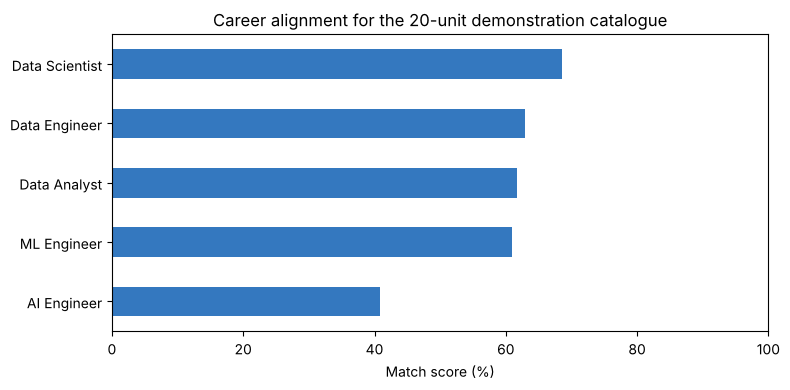

In [3]:
display(ranking[['career', 'matched_skills', 'priority_gaps', 'explanation']])
ax = ranking.sort_values('match_percent').plot.barh(x='career', y='match_percent', legend=False, color='#3478bf', figsize=(8, 4))
ax.set_xlabel('Match score (%)')
ax.set_ylabel('')
ax.set_xlim(0, 100)
ax.set_title('Career alignment for the 20-unit demonstration catalogue')
plt.tight_layout()
(HERE / 'figures').mkdir(exist_ok=True)
plt.savefig(HERE / 'figures/career_match_demo.png', dpi=300, bbox_inches='tight')
plt.show()

## Interpretation

A higher score means that the selected written materials cover more of the career's high-demand skills. It does not measure skill mastery or the probability of employment. Semantic evidence should be labelled as possible because Step 4 reports lower precision for semantic additions than for exact matches.